In [1]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset("Tobi-Bueck/customer-support-tickets", split="train")
df = ds.to_pandas()
print(df.shape)
df.head()

c:\Users\Asmin\projects\helpdesk-ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Asmin\projects\helpdesk-ai\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Asmin\.cache\huggingface\hub\datasets--Tobi-Bueck--customer-support-tickets. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrato

(61765, 16)


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,high,de,51.0,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51.0,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51.0,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",We appreciate you reaching out with your billi...,Request,Billing and Payments,low,en,51.0,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Thank you for your inquiry. Our product suppor...,Problem,Sales and Pre-Sales,medium,en,51.0,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN


In [2]:
import os
os.makedirs("raw", exist_ok=True)
df.to_parquet("raw/tickets_raw.parquet", index=False)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61765 entries, 0 to 61764
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   subject   56466 non-null  str    
 1   body      61763 non-null  str    
 2   answer    48576 non-null  str    
 3   type      48587 non-null  str    
 4   queue     61765 non-null  str    
 5   priority  61765 non-null  str    
 6   language  61765 non-null  str    
 7   version   28587 non-null  float64
 8   tag_1     48587 non-null  str    
 9   tag_2     48528 non-null  str    
 10  tag_3     48356 non-null  str    
 11  tag_4     43990 non-null  str    
 12  tag_5     27636 non-null  str    
 13  tag_6     13225 non-null  str    
 14  tag_7     5968 non-null   str    
 15  tag_8     2472 non-null   str    
dtypes: float64(1), str(15)
memory usage: 57.2 MB


In [4]:
missing = (df.isnull().mean() * 100).round(1).sort_values(ascending=False)
missing

tag_8       96.0
tag_7       90.3
tag_6       78.6
tag_5       55.3
version     53.7
tag_4       28.8
tag_3       21.7
answer      21.4
tag_2       21.4
type        21.3
tag_1       21.3
subject      8.6
language     0.0
priority     0.0
queue        0.0
body         0.0
dtype: float64

In [5]:
for col in ["type", "priority", "language", "version"]:
    print(f"\n=== {col} ===")
    print(df[col].value_counts(dropna=False))

print("\nNumber of queues:", df["queue"].nunique())
df["queue"].value_counts().head(15)


=== type ===
type
Incident    19444
Request     13950
NaN         13178
Problem     10196
Change       4997
Name: count, dtype: int64

=== priority ===
priority
medium      23378
high        21925
low         12765
critical     1914
very_low     1783
Name: count, dtype: int64

=== language ===
language
de    33504
en    28261
Name: count, dtype: int64

=== version ===
version
NaN      33178
400.0    18599
52.0      9119
51.0       869
Name: count, dtype: int64

Number of queues: 52


queue
Technical Support                      14186
Product Support                         8960
Customer Service                        7420
IT Support                              5725
Billing and Payments                    4874
Returns and Exchanges                   2438
Service Outages and Maintenance         1912
Sales and Pre-Sales                     1490
Human Resources                          914
General Inquiry                          668
Pets & Animals/Pet Services              386
News                                     383
IT & Technology/Security Operations      365
Autos & Vehicles/Sales                   364
Health/Medical Services                  362
Name: count, dtype: int64

       subject_len  body_len
count      61765.0   61765.0
mean          43.0     419.0
std           23.0     224.0
min            0.0       0.0
25%           31.0     234.0
50%           43.0     415.0
75%           56.0     587.0
max          675.0    2259.0


Matplotlib is building the font cache; this may take a moment.


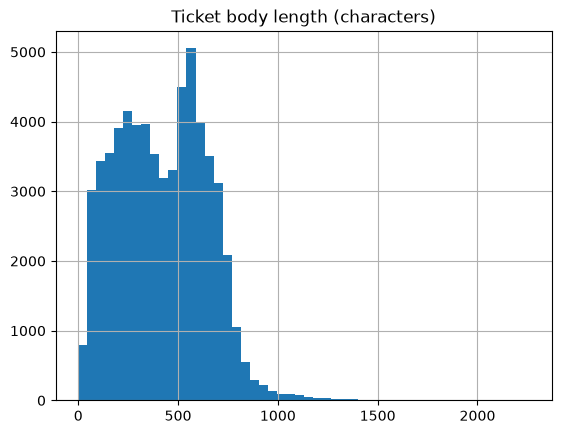

In [6]:
df["body_len"] = df["body"].fillna("").str.len()
df["subject_len"] = df["subject"].fillna("").str.len()
print(df[["subject_len", "body_len"]].describe().round(0))

import matplotlib.pyplot as plt
df["body_len"].clip(upper=2500).hist(bins=50)
plt.title("Ticket body length (characters)")
plt.show()

       subject_len  body_len
count      61765.0   61765.0
mean          43.0     419.0
std           23.0     224.0
min            0.0       0.0
25%           31.0     234.0
50%           43.0     415.0
75%           56.0     587.0
max          675.0    2259.0


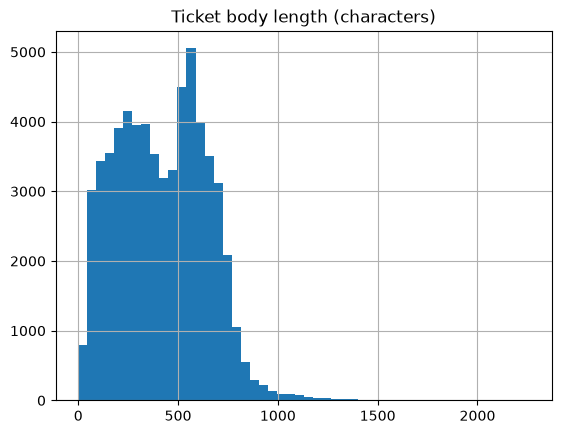

In [7]:
df["body_len"] = df["body"].fillna("").str.len()
df["subject_len"] = df["subject"].fillna("").str.len()
print(df[["subject_len", "body_len"]].describe().round(0))

import matplotlib.pyplot as plt
df["body_len"].clip(upper=2500).hist(bins=50)
plt.title("Ticket body length (characters)")
plt.show()

In [8]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Same subject + body:", df.duplicated(subset=["subject", "body"]).sum())
print("Same body only:", df.duplicated(subset=["body"]).sum())

Exact duplicate rows: 0
Same subject + body: 8306
Same body only: 8400


In [9]:
tag_cols = [c for c in df.columns if c.startswith("tag_")]
df["n_tags"] = df[tag_cols].notna().sum(axis=1)
print(df["n_tags"].value_counts().sort_index())

all_tags = df[tag_cols].stack()
print("\nUnique tags:", all_tags.nunique())
all_tags.str.lower().str.strip().value_counts().head(20)

n_tags
0    13178
1       59
2      172
3     4366
4    16354
5    14411
6     7257
7     3496
8     2472
Name: count, dtype: int64

Unique tags: 2150


tech support     24556
it               24327
performance      20003
feedback         14704
bug              14064
documentation    13229
security         11800
feature          10129
disruption        7105
outage            6262
technical         5806
network           5583
product           5100
resolution        4174
sales             3959
guidance          3031
crash             2963
recovery          2826
billing           2786
hardware          2493
Name: count, dtype: int64

In [10]:
tag_cols = [c for c in df.columns if c.startswith("tag_")]
df["n_tags"] = df[tag_cols].notna().sum(axis=1)
print(df["n_tags"].value_counts().sort_index())

all_tags = df[tag_cols].stack()
print("\nUnique tags:", all_tags.nunique())
all_tags.str.lower().str.strip().value_counts().head(20)

n_tags
0    13178
1       59
2      172
3     4366
4    16354
5    14411
6     7257
7     3496
8     2472
Name: count, dtype: int64

Unique tags: 2150


tech support     24556
it               24327
performance      20003
feedback         14704
bug              14064
documentation    13229
security         11800
feature          10129
disruption        7105
outage            6262
technical         5806
network           5583
product           5100
resolution        4174
sales             3959
guidance          3031
crash             2963
recovery          2826
billing           2786
hardware          2493
Name: count, dtype: int64

In [11]:
for text in df["body"].dropna().sample(5, random_state=1):
    print(text[:400], "\n" + "-" * 60)

Customer Support, we are looking to discuss the implementation of improved digital marketing strategies for the NZXT Kraken Z63 and related products. Our goal is to enhance brand visibility and engagement. We would like to explore options such as social media campaigns, influencer partnerships, and targeted advertising. Could you please provide guidance on available approaches and resources? We ar 
------------------------------------------------------------
Seeking assistance with security procedures 
------------------------------------------------------------
Ich bin interessiert, mehr über die Preisgestaltung der Projektmanagement-SaaS-Funktionen zu erfahren. Könnten Sie detaillierte Informationen zu den verschiedenen Plänen und den enthaltenen Funktionen geben? Ich würde gerne erfahren, welche Rabatte und Promotionsaktionen zur Verfügung stehen. Darüber hinaus wäre ich daran interessiert, zu erfahren, ob die Plattform skalierbar ist, um mein Geschäft 
-----------------------------

   # Ticket data profile (Week 2)

   - Rows: ...  | Columns: ...
   - Missing: subject ...%, body ...%, answer ...%
   - Priority levels: ... (balance: ...)
   - Queues: ... (top 10 cover ...%)
   - Languages: en ...%, de ...%
   - Duplicates: exact ..., subject+body ...
   - Very short bodies (<10 chars): ...
   - Noise seen in text: signatures / HTML / emails / phone numbers ...

   ## To fix in clean.py (Thursday)
   1. ...
   2. ...
   3. ...